In [249]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import random
import asyncio
import numpy as np
import nest_asyncio
from dotenv.main import load_dotenv

load_dotenv()
REPO_PATH = os.getenv('REPO_PATH')

TRIVIA_QA_PATH = os.getenv('TRIVIA_QA_PATH')
Natural_Questions_PATH = os.getenv('Natural_Questions_PATH')
SQUAD_PATH = os.getenv('SQUAD_PATH')

sys.path.append(REPO_PATH)

nest_asyncio.apply()

def load_json(file_path):
    with open(file_path, "r", encoding="utf-8") as file:
        return json.load(file)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 1. Load datasets:
Load all three source datasets and structure them as question-answer pairs.

In [3]:
from knowledge_maze.create_dataset.load_datasets import load_data
load_data(f"{REPO_PATH}\data_files\extracted_data.json")

Processing SQuAD: 100%|████████████████████████████████████████████████████████████| 442/442 [00:00<00:00, 1002.85it/s]


Loaded 272007 question-answer pairs in total.


In [449]:
# Load from saved dataset:
extracted_data = load_json(f"{REPO_PATH}\data_files\extracted_data.json")

# 2. Data preprocess:
- Filter out problematic questions (long answers, answers within questions, complex questions)
- Classify answers by types of entities
- Update entity types in the dataset

Filtering WH questions: 100%|██████████████████████████████████████████████| 272007/272007 [00:00<00:00, 423863.56it/s]


244638 out of 272007 samples have passed (89.9%).


Filtering self containing questions: 100%|█████████████████████████████████| 244638/244638 [00:02<00:00, 105611.90it/s]


242584 out of 244638 samples have passed (99.2%).


Filtering out long questions: 100%|███████████████████████████████████████| 242584/242584 [00:00<00:00, 1637240.09it/s]


...

9038 numerical samples found (4.0%).


Extracting date & time samples: 100%|██████████████████████████████████████| 226408/226408 [00:00<00:00, 539209.82it/s]


22159 date & time samples found (9.8%).


Extracting rest of the relevant samples: 100%|████████████████████████████| 226408/226408 [00:00<00:00, 3223500.75it/s]


105584 relevant samples found (46.6%).
Generating pie chart...


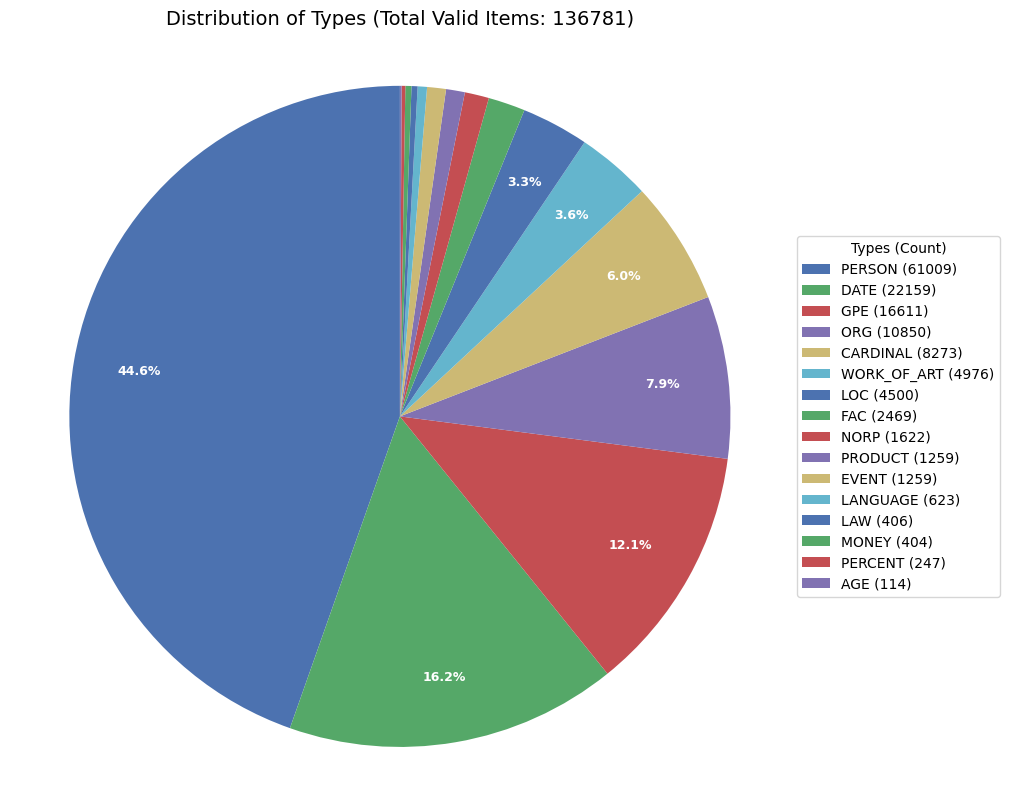

In [457]:
from knowledge_maze.create_dataset.preprocess import preprocess
processed_data = preprocess(extracted_data, output_path=f"{REPO_PATH}\data_files\processed_data.json")

In [442]:
# Load from saved dataset:
processed_data = load_json(f"{REPO_PATH}\data_files\processed_data.json")

# 3. Group questions:
- Group Questions togather based on shared answers
- Questions with numerical and date answers are grouped by closed value answers instead of exact match
- Filter out questions that are too semantically similar
- Filter out ambiguous questions
- Create candidate reasoning chains for the dataset

Dividing data by type...
Clustering data...
Creating reasoning paths for general clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 29/29 [01:16<00:00,  2.63s/it]
Creating similarity graphs and filtering questions: 100%|████████████████████████| 8359/8359 [00:06<00:00, 1348.57it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 8359/8359 [00:00<00:00, 737255.54it/s]


Creating reasoning paths for numerical clusters...


Generating question embeddings: 100%|████████████████████████████████████████████████████| 5/5 [00:12<00:00,  2.44s/it]
Creating similarity graphs and filtering questions: 100%|██████████████████████████████| 42/42 [00:06<00:00,  6.72it/s]
Splitting large clusters: 100%|███████████████████████████████████████████████████████| 42/42 [00:00<00:00, 103.24it/s]


Creating reasoning paths for date clusters...


Generating question embeddings: 100%|██████████████████████████████████████████████████| 11/11 [00:26<00:00,  2.43s/it]
Creating similarity graphs and filtering questions: 100%|█████████████████████████| 1106/1106 [00:06<00:00, 174.38it/s]
Splitting large clusters: 100%|████████████████████████████████████████████████| 1106/1106 [00:00<00:00, 135513.56it/s]


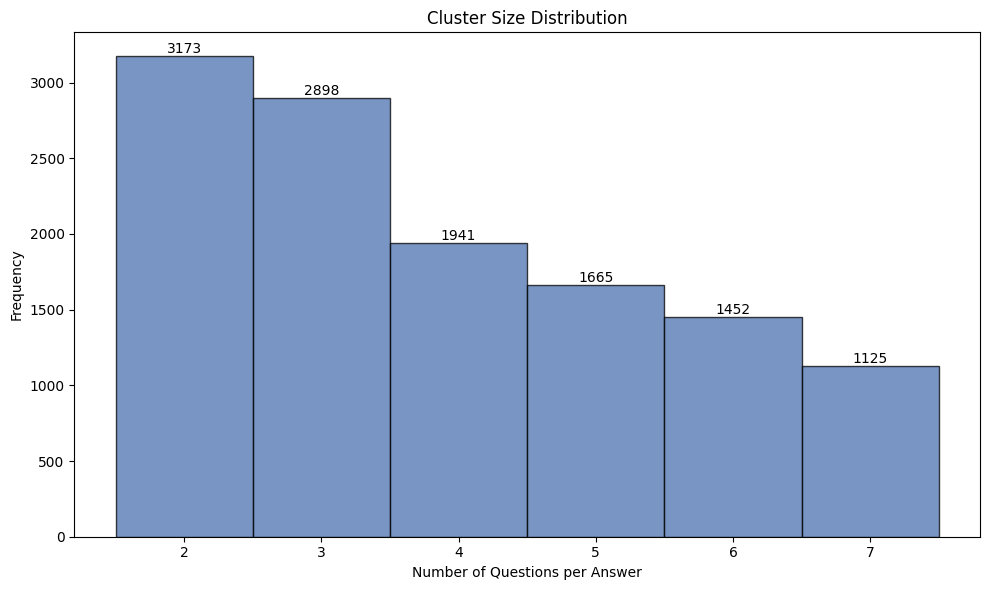

In [458]:
from knowledge_maze.create_dataset.create_reasoning_path import create_paths
cluster_data = await create_paths(processed_data, output_path=f"{REPO_PATH}\data_files\cluster_data.json")

Generating question embeddings: 100%|████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.73s/it]

Answer: ('Costa Rica', 'GPE')
Questions before filtering:
1. Which country does the airline LACSA come from?
2. Which country does the airline Sansa come from?
3. The controversial Boruca Dam is in which South American country?
4. The volcano Irazu is in which Central American country?


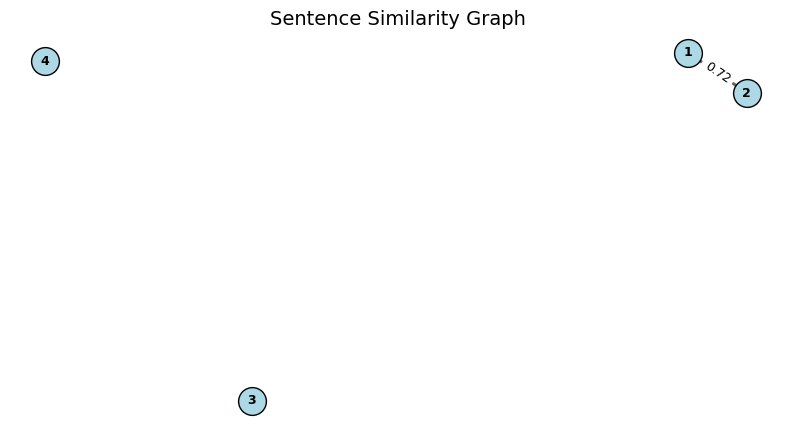

Questions after filtering:
1. Which country does the airline Sansa come from?
2. The controversial Boruca Dam is in which South American country?
3. The volcano Irazu is in which Central American country?


In [4]:
# Plot graph example - (filtering process):
from knowledge_maze.create_dataset.create_reasoning_path import display_random_sample
display_random_sample(processed_data)

In [3]:
# Load from saved dataset:
cluster_data = load_json(f"{REPO_PATH}\data_files\cluster_data.json")

# 4. Create Structured Data:
- Split questions list into reasoning paths and extract main question
- Create counter-factual answers
- Assign paragraph ids for each question pair
- Make an organized data structure for later usage and display data samples efficiently

**Dataset QA Structure:**
```
{
    'ID': '',
    'Question': '',
    'Answers': {
        'Memory answer': '',
        'Counter answer 1': '',
        'Counter answer 2': '',
        'Distractor answer': ''
    },
    'Answer type': '',
    'Reasoning path 1':[
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        ...
    ],
    'Reasoning path 2':[
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        {'Previous question': '', 'Next question': '', 'Paragraph': ''},
        ...
    ]
    'Distractor paragraphs': []
}
```

Creating dataset QA samples: 100%|██████████████████████████████████████████████| 12254/12254 [00:30<00:00, 398.77it/s]


Generating counter answers for numerical data:


Usage cost: 0.0317$ (Estimated: 0.03$): 100%|████████████████████████████████████████| 952/952 [00:25<00:00, 36.63it/s]


Generating counter answers for general data:


Usage cost: 0.3557$ (Estimated: 0.36$): 100%|██████████████████████████████████████| 8311/8311 [03:23<00:00, 40.81it/s]


Generating counter answers for date data:


Usage cost: 0.0000$ (Estimated: 0.00$): 100%|██████████████████████████████████████| 2991/2991 [00:40<00:00, 73.30it/s]


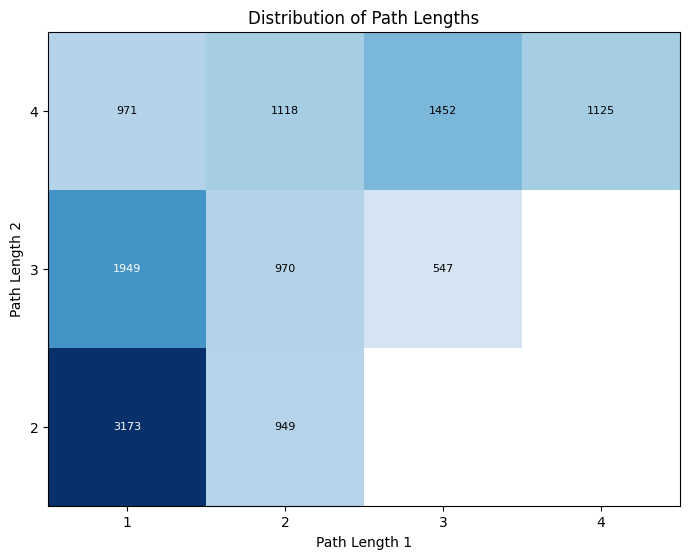

In [459]:
from knowledge_maze.create_dataset.create_data_qa import create_data_qa
knowledge_maze_qa = await create_data_qa(cluster_data, output_path=f"{REPO_PATH}\data_files\knowledge_maze_qa.json")

In [460]:
# Show random sample:
from knowledge_maze.create_dataset.create_data_qa import display_qa_sample
display_qa_sample(random.choice(knowledge_maze_qa))

ID: daa12961-452e-4b27-b36e-60754a40f153
Question: Siddhartha Gautama became better known as who?
Answer (Original): Gautama Buddha
Answer type: PERSON

Answers:
- Gautama Buddha (Memory answer)
- Laozi (Counter answer 1)
- Confucius (Counter answer 2)
- Zhuangzi (Distractor answer)

Sub-questions path 1:
 1. Siddhartha Gautama became better known as who? (Gautama Buddha)
 2. according to legend who created the chinese zodiac (Gautama Buddha)
 3. Which Sanskrit word means ‘awakened one’? (Gautama Buddha)
 4. Which religious founder rode a horse called 'Kantaka'? (Gautama Buddha)

Sub-questions path 2:
 1. Siddhartha Gautama became better known as who? (Gautama Buddha)
 2. Who taught directly or indirectly to all other Buddhas? (Gautama Buddha)
 3. Who is believed to have achieved enlightenment first? (Gautama Buddha)
 4. Devadatta repeatedly tried to kill which religious leader? (Gautama Buddha)


In [382]:
# Load from saved dataset:
knowledge_maze_qa = load_json(f"{REPO_PATH}\data_files\knowledge_maze_qa.json")

# 5. Generate paragraphs:

### TODOS:
- refactor generate_paragraphs to be create_data_paragraphs to crate the paragraphs part of the dataset
- in paragraph creation need to think of a way to make it case sensitive, or make a prompt with reasoning process...
- maybe add a connection paragraph between the reasoning paths for the memory vs context scenario?